# The World Cup Effect: EA SPORTS FC activity on Steam

**Questions**

1. **World Cup impact:** do World Cup periods coincide with unusually high Steam activity compared with non-World-Cup years?
2. **Timing:** when do increases happen relative to tournament milestones, EA content and promotions?
3. **Discounts:** how does activity behave around Steam price cuts, especially June 2026 compared with earlier cuts?
4. **Persistence:** does elevated activity last after the tournament and promotions end?
5. **Implications:** what could EA investigate or test next?

**Metric:** average concurrent players on Steam (PC only), from SteamDB. This is how many people were playing at the same time, averaged over a day or month. It is not unique players, sales or retention.

**Approach:** the earlier and later annual releases act as *observational* comparison years. They differ in age, promotions and the wider Steam population, so differences are described, not attributed to the World Cup.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import textwrap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED, FIGURES = ROOT / "data/raw", ROOT / "data/processed", ROOT / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)

GAMES = {1811260: "FIFA 23", 2195250: "FC 24", 2669320: "FC 25", 3405690: "FC 26"}
# Steam release dates (Steam store API, checked 2026-11-10)
STEAM_RELEASE = {"FIFA 23": "2022-09-30", "FC 24": "2023-09-28", "FC 25": "2024-09-26",
                 "FC 26": "2025-09-25", "FC 27": "2026-09-24"}

# Event dates; sources are listed in sources.md
WC_2022 = (pd.Timestamp("2022-11-20"), pd.Timestamp("2022-12-18"))
WC_2026 = (pd.Timestamp("2026-06-11"), pd.Timestamp("2026-07-19"))
FESTIVAL_2026 = (pd.Timestamp("2026-06-05"), pd.Timestamp("2026-07-24"))  # FUT campaigns + Pele login reward window
pd.set_option("display.width", 140)

# Raw files are not redistributed in the repository; see data/raw/README.md for how to download them
REQUIRED = [f"steamdb_chart_{a}.csv" for a in GAMES] + ["steamdb_price_3405690_CAD.csv", "steamdb_price_1811260_CAD.csv"] \
           + [f"steamcharts/steamcharts_{a}.html" for a in GAMES]
missing = [f for f in REQUIRED if not (RAW / f).exists()]
if missing:
    raise FileNotFoundError("Missing raw files (see data/raw/README.md for download steps): " + ", ".join(missing))

## 1. Load and clean the daily data

SteamDB's CSV export mixes resolutions: one row per day for most of the history, then hourly and 10-minute snapshots for the most recent month. Checks done during data collection (see `data/raw/README.md`):

- `Average Players` on each 00:00 row is that day's average concurrent players. Where 10-minute snapshots exist, it equals their daily mean exactly.
- `Players` on daily rows is the day's **peak**. On sub-daily rows it is a single snapshot, so the peak is only kept for the daily-resolution period.
- The last day in each file (10 Nov 2026) is incomplete and dropped.

In [2]:
def load_daily(app_id):
    raw = pd.read_csv(RAW / f"steamdb_chart_{app_id}.csv", encoding="utf-8-sig", parse_dates=["DateTime"])
    raw = raw.sort_values("DateTime")
    # first timestamp where rows are less than a day apart = start of sub-daily data
    sub_daily_start = raw.loc[raw["DateTime"].diff() < pd.Timedelta("1D"), "DateTime"].min().normalize()
    daily = raw[(raw["DateTime"].dt.strftime("%H:%M") == "00:00") & raw["Average Players"].notna()].copy()
    daily["date"] = daily["DateTime"].dt.normalize()
    daily = daily[daily["date"] < raw["DateTime"].max().normalize()]          # drop incomplete last day
    daily["peak_players"] = daily["Players"].where(daily["date"] < sub_daily_start)
    return pd.DataFrame({"game": GAMES[app_id], "app_id": app_id, "date": daily["date"],
                         "avg_players": daily["Average Players"].astype(int),
                         "peak_players": daily["peak_players"].astype("Int64")})

daily = pd.concat([load_daily(a) for a in GAMES], ignore_index=True)

# Data-quality checks
for g, d in daily.groupby("game"):
    full_range = pd.date_range(d["date"].min(), d["date"].max())
    assert d["date"].is_unique and len(full_range) == len(d), f"{g}: missing or duplicate days"
    assert d["avg_players"].notna().all()
summary = daily.groupby("game").agg(first_day=("date", "min"), last_day=("date", "max"), days=("date", "size"),
                                    last_daily_peak=("peak_players", lambda s: s.dropna().index.max()))
summary["last_daily_peak"] = daily.loc[summary["last_daily_peak"], "date"].values
summary

,first_day,last_day,days,last_daily_peak
game,,,,
FC 24,2023-09-28,2026-11-09,1139,2026-10-10
FC 25,2024-09-27,2026-11-09,774,2026-10-10
FC 26,2025-09-25,2026-11-09,411,2026-10-10
FIFA 23,2022-09-29,2026-11-09,1503,2026-10-10


In [3]:
daily.to_csv(PROCESSED / "daily_players.csv", index=False)
daily.head()

,game,app_id,date,avg_players,peak_players
0,FIFA 23,1811260,2022-09-29,42706,51845
1,FIFA 23,1811260,2022-09-30,44822,75547
2,FIFA 23,1811260,2022-10-01,53582,75749
3,FIFA 23,1811260,2022-10-02,51957,78449
4,FIFA 23,1811260,2022-10-03,42098,69646


## 2. Monthly averages and the Steam Charts cross-check

Monthly average = mean of the daily averages in that calendar month. Only complete months are kept (every day present). This drops each game's partial launch month (late September) and November 2026.

In [4]:
monthly = (daily.assign(month=daily["date"].dt.to_period("M"))
           .groupby(["game", "month"])
           .agg(avg_players=("avg_players", "mean"), days=("date", "size"), peak_players=("peak_players", "max"))
           .reset_index())
monthly = monthly[monthly["days"] == monthly["month"].dt.days_in_month]   # complete months only
monthly["avg_players"] = monthly["avg_players"].round(0).astype(int)
monthly["mom_pct_change"] = monthly.groupby("game")["avg_players"].pct_change().mul(100).round(1)
monthly["month_start"] = monthly["month"].dt.start_time
monthly.groupby("game")["month"].agg(["min", "max", "size"])

,min,max,size
game,,,
FC 24,2023-10,2026-10,37
FC 25,2024-10,2026-10,25
FC 26,2025-10,2026-10,13
FIFA 23,2022-10,2026-10,49


In [5]:
# Cross-check against Steam Charts monthly averages (pages saved in data/raw/steamcharts/, retrieved 2026-11-10)
def steamcharts(app_id):
    t = pd.read_html(RAW / "steamcharts" / f"steamcharts_{app_id}.html")[0]
    t = t[t["Month"] != "Last 30 Days"]
    return pd.DataFrame({"game": GAMES[app_id], "month": pd.to_datetime(t["Month"], format="%B %Y").dt.to_period("M"),
                         "steamcharts_avg": t["Avg. Players"].astype(float)})

check = monthly.merge(pd.concat([steamcharts(a) for a in GAMES]), on=["game", "month"])
check["diff_pct"] = (check["avg_players"] / check["steamcharts_avg"] - 1) * 100
print(check.groupby("game")["diff_pct"].describe()[["count", "50%", "min", "max"]].round(1))
print("\nMonths differing by more than 2%:")
print(check.loc[check["diff_pct"].abs() > 2, ["game", "month", "avg_players", "steamcharts_avg", "diff_pct"]].round(1).to_string(index=False))

         count  50%  min  max
game                         
FC 24     37.0  0.1 -0.5  1.0
FC 25     25.0  0.3 -0.1  1.2
FC 26     13.0  0.4 -4.8  1.0
FIFA 23   49.0  0.1 -1.0  6.4

Months differing by more than 2%:
   game   month  avg_players  steamcharts_avg  diff_pct
  FC 26 2025-11        35958          37779.0      -4.8
FIFA 23 2022-10        37204          35980.0       3.4
FIFA 23 2025-12          768            752.2       2.1
FIFA 23 2026-01          743            718.8       3.4
FIFA 23 2026-02          697            678.3       2.8
FIFA 23 2026-03          651            612.8       6.2
FIFA 23 2026-04          686            665.0       3.2
FIFA 23 2026-06          721            703.3       2.5
FIFA 23 2026-08          705            674.6       4.5
FIFA 23 2026-09          577            542.1       6.4


The two sources agree closely (median difference under 0.5%). Larger gaps are concentrated in FIFA 23's 2026 months, when it had under 1,000 players and small sampling differences matter more. SteamDB is used throughout, so all comparisons share one method.

In [6]:
monthly.drop(columns="month_start").to_csv(PROCESSED / "monthly_players.csv", index=False)

## 3. Q1 — Summer: FC 26 (2026 World Cup) against FC 24 and FC 25

Each game is indexed to its own May = 100. All three are at the same point in the release cycle (8–13 months after launch), so the index compares *shape*, not size.

Comparison-year caveats: summer 2024 had UEFA EURO 2024 (14 Jun–14 Jul), with a free EURO update in FC 24, so it is not a tournament-free year. Summer 2025 had the FIFA Club World Cup. The next annual game launched each September (FC 27 on 24 Sep 2026).

In [7]:
def indexed(game, start, end, base_months):
    m = monthly[(monthly["game"] == game) & (monthly["month"] >= pd.Period(start, "M")) & (monthly["month"] <= pd.Period(end, "M"))].copy()
    base = monthly[(monthly["game"] == game) & monthly["month"].isin([pd.Period(b, "M") for b in base_months])]["avg_players"]
    assert len(base) == len(base_months), f"baseline months missing for {game}"
    m["index"] = m["avg_players"] / base.mean() * 100
    m["label"] = m["month"].dt.strftime("%b")
    return m

SUMMER = [("FC 24", 2024), ("FC 25", 2025), ("FC 26", 2026)]
summer = {g: indexed(g, f"{y}-05", f"{y}-10", [f"{y}-05"]) for g, y in SUMMER}
summer_tbl = pd.DataFrame({f"{g} ({y})": summer[g].set_index("label")["index"].round(0) for g, y in SUMMER})
summer_tbl["FC 26 minus control avg (pts)"] = summer_tbl.iloc[:, 2] - summer_tbl.iloc[:, :2].mean(axis=1)
print("Index, May = 100")
summer_tbl

Index, May = 100


,FC 24 (2024),FC 25 (2025),FC 26 (2026),FC 26 minus control avg (pts)
label,,,,
May,100.0,100.0,100.0,0.0
Jun,87.0,97.0,162.0,70.0
Jul,109.0,106.0,223.0,115.5
Aug,92.0,82.0,165.0,78.0
Sep,56.0,51.0,93.0,39.5
Oct,32.0,32.0,52.0,20.0


In [8]:
# Robustness: use the March-May average as the baseline instead of May alone
summer_rb = {g: indexed(g, f"{y}-05", f"{y}-10", [f"{y}-03", f"{y}-04", f"{y}-05"]) for g, y in SUMMER}
print("Index, Mar-May average = 100")
pd.DataFrame({f"{g} ({y})": summer_rb[g].set_index("label")["index"].round(0) for g, y in SUMMER})

Index, Mar-May average = 100


,FC 24 (2024),FC 25 (2025),FC 26 (2026)
label,,,
May,112.0,105.0,106.0
Jun,97.0,101.0,171.0
Jul,122.0,111.0,235.0
Aug,102.0,86.0,174.0
Sep,62.0,54.0,99.0
Oct,36.0,34.0,55.0


In [9]:
# Raw monthly averages behind the index
monthly[monthly["month"].dt.month.isin(range(3, 11)) & monthly.apply(lambda r: (r["game"], r["month"].year) in SUMMER, axis=1)] \
    .pivot(index="month", columns="game", values="avg_players")

game,FC 24,FC 25,FC 26
month,,,
2024-03,39570.0,NaN,NaN
2024-04,40714.0,NaN,NaN
2024-05,47530.0,NaN,NaN
2024-06,41371.0,NaN,NaN
2024-07,51879.0,NaN,NaN
2024-08,43556.0,NaN,NaN
2024-09,26408.0,NaN,NaN
2024-10,15136.0,NaN,NaN
2025-03,NaN,51740.0,NaN


## 4. Q1 — Winter: FIFA 23 (2022 World Cup) against FC 24, FC 25 and FC 26

Indexed to October = 100, the first full month after each launch. The core window is October–January. February–April is included to show whether any gap is specific to the tournament.

In [10]:
WINTER = [("FIFA 23", 2022), ("FC 24", 2023), ("FC 25", 2024), ("FC 26", 2025)]
winter = {g: indexed(g, f"{y}-10", f"{y+1}-04", [f"{y}-10"]) for g, y in WINTER}
winter_tbl = pd.DataFrame({f"{g} ({y}/{str(y+1)[2:]})": winter[g].set_index("label")["index"].round(0) for g, y in WINTER})
winter_tbl["FIFA 23 minus control avg (pts)"] = winter_tbl.iloc[:, 0] - winter_tbl.iloc[:, 1:].mean(axis=1)
print("Index, October = 100")
winter_tbl

Index, October = 100


,FIFA 23 (2022/23),FC 24 (2023/24),FC 25 (2024/25),FC 26 (2025/26),FIFA 23 minus control avg (pts)
label,,,,,
Oct,100.0,100.0,100.0,100.0,0.000000
Nov,81.0,80.0,76.0,79.0,2.666667
Dec,131.0,97.0,87.0,95.0,38.000000
Jan,160.0,113.0,104.0,110.0,51.000000
Feb,131.0,90.0,94.0,90.0,39.666667
Mar,107.0,95.0,101.0,90.0,11.666667
Apr,130.0,98.0,89.0,96.0,35.666667


**Sensitivity check.** The October baseline is a single month near launch. To test whether it drives the result, each game's October, December and January are expressed as a share of its own **February–April** average. Those months come *after* the 2022 tournament, so this is a post-tournament reference level, not an alternative pre-event baseline.

In [11]:
# Sensitivity check: Oct, Dec and Jan as % of each game's own Feb-Apr average (post-tournament reference)
rows = []
for g, y in WINTER:
    m = monthly[monthly["game"] == g].set_index("month")["avg_players"]
    later = m[[pd.Period(f"{y+1}-0{k}", "M") for k in (2, 3, 4)]].mean()
    rows.append({"game": g, "Oct as % of Feb-Apr": m[pd.Period(f"{y}-10", "M")] / later * 100,
                 "Dec as % of Feb-Apr": m[pd.Period(f"{y}-12", "M")] / later * 100,
                 "Jan as % of Feb-Apr": m[pd.Period(f"{y+1}-01", "M")] / later * 100})
pd.DataFrame(rows).set_index("game").round(0)

,Oct as % of Feb-Apr,Dec as % of Feb-Apr,Jan as % of Feb-Apr
game,,,
FIFA 23,82.0,107.0,131.0
FC 24,106.0,103.0,120.0
FC 25,105.0,92.0,110.0
FC 26,109.0,103.0,119.0


The October baseline flatters FIFA 23. Its October was low relative to the rest of its season (82% of its Feb–Apr level, versus 105–109% for the other three games). Measured against that post-tournament reference, FIFA 23's December (107%) is only slightly above the comparison games (92–103%), and its January (131% vs 110–120%) is the clearer outlier. FIFA 23 also stayed well above the comparison games in February and April, long after the final. So the 2022 winter gap is real but sensitive to the reference period, and it can't be pinned to the tournament window.

In [12]:
# 7-day before/after comparison used for every event in this notebook.
# Event day D = the UTC calendar date of the event (or of the price change).
#   before = daily averages for D-7 ... D-1   (7 days)
#   after  = daily averages for D+1 ... D+7   (7 days)
# D itself is excluded, because most events start part-way through the day (price changes ~17:00-18:00 UTC).
# Each window contains every weekday exactly once, so weekend highs don't bias the comparison.
def window_change(game, event_date, days=7):
    s = daily[daily["game"] == game].set_index("date")["avg_players"]
    d = pd.Timestamp(event_date)
    before = s[d - pd.Timedelta(days=days): d - pd.Timedelta(days=1)]
    after = s[d + pd.Timedelta(days=1): d + pd.Timedelta(days=days)]
    if len(before) < days or len(after) < days:
        return pd.Series({"avg_7d_before": np.nan, "avg_7d_after": np.nan, "change_pct": np.nan})
    assert before.index.dayofweek.nunique() == days and after.index.dayofweek.nunique() == days
    return pd.Series({"avg_7d_before": before.mean(), "avg_7d_after": after.mean(),
                      "change_pct": (after.mean() / before.mean() - 1) * 100})

def window_dates(event_date, days=7):
    d = pd.Timestamp(event_date)
    f = lambda x: x.strftime("%d %b %Y")
    return f"{f(d - pd.Timedelta(days=days))}–{f(d - pd.Timedelta(days=1))} vs {f(d + pd.Timedelta(days=1))}–{f(d + pd.Timedelta(days=days))}"

# Comparison years use the same calendar dates shifted by whole years (weekdays differ, but each window is still a full week).

fifa23_events = pd.DataFrame([
    ("2022-11-09", "Free World Cup update released"),
    ("2022-11-20", "World Cup kick-off"),
    ("2022-12-18", "World Cup final"),
], columns=["date", "event"])

def same_dates_winter(d):
    d = pd.Timestamp(d)
    return pd.Series({"FIFA 23 (2022) %": window_change("FIFA 23", d)["change_pct"],
                      "FC 24 same dates 2023 %": window_change("FC 24", d + pd.DateOffset(years=1))["change_pct"],
                      "FC 25 same dates 2024 %": window_change("FC 25", d + pd.DateOffset(years=2))["change_pct"],
                      "FC 26 same dates 2025 %": window_change("FC 26", d + pd.DateOffset(years=3))["change_pct"]})

fifa23_events["windows (before vs after)"] = fifa23_events["date"].apply(window_dates)
fifa23_events.join(fifa23_events["date"].apply(same_dates_winter)).round(1)

,date,event,windows (before vs after),FIFA 23 (2022) %,FC 24 same dates 2023 %,FC 25 same dates 2024 %,FC 26 same dates 2025 %
0,2022-11-09,Free World Cup update released,02 Nov 2022–08 Nov 2022 vs 10 Nov 2022–16 Nov ...,7.7,-8.6,-1.2,-11.2
1,2022-11-20,World Cup kick-off,13 Nov 2022–19 Nov 2022 vs 21 Nov 2022–27 Nov ...,9.9,29.9,4.8,26.2
2,2022-12-18,World Cup final,11 Dec 2022–17 Dec 2022 vs 19 Dec 2022–25 Dec ...,31.2,7.7,21.4,23.0


After EA's free World Cup update (9 Nov), FIFA 23 rose 8% while the same dates in other years fell 1–11%. A modest rise, but above the comparison range. After kick-off (20 Nov) it rose 10%, within the range of other years (+5% to +30%; late November includes Black Friday and Steam's autumn sale every year). The kick-off "after" window also contains the start of a 40% FIFA 23 discount (22 Nov). The week after the final (+31%) is above the comparison years (+8% to +23%), but late December includes the holidays and Steam's winter sale every year. The daily data below shows when FIFA 23 actually stepped up.

In [13]:
dec = daily[daily["game"] == "FIFA 23"].set_index("date").loc["2022-12-05":"2022-12-24", ["avg_players"]]
dec["weekday"] = dec.index.day_name()
dec.T

date,2022-12-05,2022-12-06,2022-12-07,2022-12-08,2022-12-09,2022-12-10,2022-12-11,2022-12-12,2022-12-13,2022-12-14,2022-12-15,2022-12-16,2022-12-17,2022-12-18,2022-12-19,2022-12-20,2022-12-21,2022-12-22,2022-12-23,2022-12-24
avg_players,26970,26596,26541,27506,32050,42246,45957,38989,39474,39579,41896,50414,62938,62242,57391,53444,55629,57873,63776,66560
weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday


FIFA 23 stepped up on two Fridays during the tournament's final weeks. From 9 Dec (quarter-final weekend) weekday levels went from about 27k to 39k, and from 16 Dec (final weekend) to about 55k. They kept rising into January.

**FIFA 23 pricing.** SteamDB's FIFA 23 price history (Canadian store) shows the 9 Dec step began the day after a **60% discount** started (8 Dec 2022, 18:03 UTC), which ran until 5 Jan 2023. A 40% discount ran 22–29 Nov 2022, during the group stage.

In [14]:
price23 = pd.read_csv(RAW / "steamdb_price_1811260_CAD.csv", encoding="utf-8-sig", parse_dates=["DateTime"])
price23 = price23.dropna(subset=["Final price"]).sort_values("DateTime").reset_index(drop=True)
price23["pct_off"] = (1 - price23["Final price"] / 89.99) * 100
p23 = price23[(price23["DateTime"] >= "2022-10-01") & (price23["DateTime"] < "2023-03-01")].copy()
p23["date"] = p23["DateTime"].dt.normalize()
p23 = p23.join(p23["date"].apply(lambda d: window_change("FIFA 23", d)))
p23["windows (before vs after)"] = p23["date"].apply(window_dates)
p23[["DateTime", "Final price", "pct_off", "windows (before vs after)", "avg_7d_before", "avg_7d_after", "change_pct"]].round(1)

,DateTime,Final price,pct_off,windows (before vs after),avg_7d_before,avg_7d_after,change_pct
3,2022-11-22 18:13:50,54.0,40.0,15 Nov 2022–21 Nov 2022 vs 23 Nov 2022–29 Nov ...,26171.7,34598.4,32.2
4,2022-11-29 18:26:23,90.0,0.0,22 Nov 2022–28 Nov 2022 vs 30 Nov 2022–06 Dec ...,32889.0,31815.9,-3.3
5,2022-12-08 18:03:20,36.0,60.0,01 Dec 2022–07 Dec 2022 vs 09 Dec 2022–15 Dec ...,31123.4,40027.3,28.6
6,2023-01-05 18:29:53,90.0,0.0,29 Dec 2022–04 Jan 2023 vs 06 Jan 2023–12 Jan ...,66521.3,60071.4,-9.7
7,2023-01-21 18:03:04,36.0,60.0,14 Jan 2023–20 Jan 2023 vs 22 Jan 2023–28 Jan ...,53686.0,59269.4,10.4
8,2023-02-02 18:03:35,90.0,0.0,26 Jan 2023–01 Feb 2023 vs 03 Feb 2023–09 Feb ...,61628.1,55186.4,-10.5


Both World Cups therefore overlapped a deep Steam discount. In 2022 the main activity step lines up with the start of the 60% discount (8 Dec), not with kick-off (20 Nov) or EA's World Cup update (9 Nov). Price history was not collected for FC 24 or FC 25, so discount timing in the comparison winters is unknown. FC 26 itself was 60% off from 18 Dec 2025.

## 5. Q2 & Q3 — FC 26 daily timing and pricing, May–August 2026

**Method:** for each event, the mean of the 7 days *before* the event day is compared with the 7 days *after* it, leaving out the event day itself. Each 7-day window holds every weekday exactly once, so weekend highs don't bias the comparison. Events that overlap can't be separated.

**Price data:** SteamDB's FC 26 price history for the **Canadian** store (CAD; list price CA$89.99). Each row is a price change.

In [15]:
price = pd.read_csv(RAW / "steamdb_price_3405690_CAD.csv", encoding="utf-8-sig", parse_dates=["DateTime"])
price = price.dropna(subset=["Final price"]).sort_values("DateTime").reset_index(drop=True)
LIST_PRICE = 89.99
price["pct_off"] = (1 - price["Final price"] / LIST_PRICE) * 100
price["prev_price"] = price["Final price"].shift()
price["hours_at_price"] = (price["DateTime"].shift(-1) - price["DateTime"]).dt.total_seconds() / 3600
price[["DateTime", "Final price", "pct_off", "hours_at_price"]].round(1)

,DateTime,Final price,pct_off,hours_at_price
0,2025-07-16 16:00:03,90.0,0.0,3050.0
1,2025-11-20 18:01:10,45.0,50.0,336.0
2,2025-12-04 18:01:13,90.0,0.0,0.2
3,2025-12-04 18:15:20,72.0,20.0,26.9
4,2025-12-05 21:10:02,90.0,0.0,116.9
5,2025-12-10 18:01:11,52.0,42.2,144.0
6,2025-12-16 18:01:14,90.0,0.0,48.2
7,2025-12-18 18:10:33,36.0,60.0,432.2
8,2026-01-05 18:24:45,90.0,0.0,33.8
9,2026-01-07 04:10:02,72.0,20.0,158.0


In [16]:
# Every price cut in FC 26's history, with the 7-day before/after activity change
cuts = price[price["Final price"] < price["prev_price"]].copy()
cuts["date"] = cuts["DateTime"].dt.normalize()
cuts = cuts.join(cuts["date"].apply(lambda d: window_change("FC 26", d)))
cuts = cuts[["date", "prev_price", "Final price", "pct_off", "hours_at_price", "avg_7d_before", "avg_7d_after", "change_pct"]]
cuts.columns = ["date", "price_before_CAD", "price_after_CAD", "pct_below_list", "hours_at_price", "avg_7d_before", "avg_7d_after", "change_pct"]
cuts.round(1)

,date,price_before_CAD,price_after_CAD,pct_below_list,hours_at_price,avg_7d_before,avg_7d_after,change_pct
1,2025-11-20,90.0,45.0,50.0,336.0,29887.4,37721.9,26.2
3,2025-12-04,90.0,72.0,20.0,26.9,44171.1,39165.7,-11.3
5,2025-12-10,90.0,52.0,42.2,144.0,40750.1,38334.1,-5.9
7,2025-12-18,90.0,36.0,60.0,432.2,38334.1,47167.3,23.0
9,2026-01-07,90.0,72.0,20.0,158.0,49248.6,43160.4,-12.4
11,2026-01-15,90.0,34.5,61.7,336.0,43160.4,54044.4,25.2
13,2026-02-05,90.0,61.5,31.7,671.9,48263.1,40661.6,-15.8
14,2026-03-05,61.5,27.0,70.0,503.2,36451.6,41107.3,12.8
16,2026-04-07,61.5,28.8,68.1,337.2,42189.3,42897.1,1.7
18,2026-04-23,51.2,27.0,70.0,336.0,45209.7,45388.3,0.4


Known overlaps (from SteamDB chart markers and EA pages): 15 Jan 2026 coincided with the Team of the Year update, with a Steam free weekend from 11 Jan in the "before" window. 4 Jun coincided with the World's Game tournament mode launch. 18 Jul fell inside the final week of the Festival of Football and the World Cup.

In [17]:
# Key 2026 summer events, with the same calendar windows in the comparison years as a seasonal benchmark
events_2026 = pd.DataFrame([
    ("2026-06-04", "World's Game mode live; price cut to 74% off"),
    ("2026-06-11", "World Cup kick-off; price cut to 80% off (17:12 UTC)"),
    ("2026-07-19", "World Cup final"),
    ("2026-07-24", "Festival of Football ends; FUTTIES launches"),
    ("2026-07-25", "Full price restored"),
], columns=["date", "event"])

def same_window_prior_years(d):
    d = pd.Timestamp(d)
    return pd.Series({"FC 26 (2026) %": window_change("FC 26", d)["change_pct"],
                      "FC 25 same dates 2025 %": window_change("FC 25", d - pd.DateOffset(years=1))["change_pct"],
                      "FC 24 same dates 2024 %": window_change("FC 24", d - pd.DateOffset(years=2))["change_pct"]})

event_tbl = events_2026.join(events_2026["date"].apply(same_window_prior_years)).round(1)
event_tbl.insert(2, "windows (before vs after)", event_tbl["date"].apply(window_dates))
event_tbl

,date,event,windows (before vs after),FC 26 (2026) %,FC 25 same dates 2025 %,FC 24 same dates 2024 %
0,2026-06-04,World's Game mode live; price cut to 74% off,28 May 2026–03 Jun 2026 vs 05 Jun 2026–11 Jun ...,20.6,-2.5,-2.3
1,2026-06-11,World Cup kick-off; price cut to 80% off (17:1...,04 Jun 2026–10 Jun 2026 vs 12 Jun 2026–18 Jun ...,45.4,-4.6,-4.6
2,2026-07-19,World Cup final,12 Jul 2026–18 Jul 2026 vs 20 Jul 2026–26 Jul ...,8.7,-3.5,0.8
3,2026-07-24,Festival of Football ends; FUTTIES launches,17 Jul 2026–23 Jul 2026 vs 25 Jul 2026–31 Jul ...,3.8,-8.8,-2.3
4,2026-07-25,Full price restored,18 Jul 2026–24 Jul 2026 vs 26 Jul 2026–01 Aug ...,-0.1,-9.8,-3.5


In [18]:
# Largest 7-day before/after increases in FC 26's history (every day with a full window on both sides)
fc26_avg = daily[daily["game"] == "FC 26"].set_index("date")["avg_players"]
all_steps = pd.Series({d: window_change("FC 26", d)["change_pct"] for d in fc26_avg.index}).dropna()
print("Days tested:", all_steps.index.min().date(), "to", all_steps.index.max().date())
print(all_steps.sort_values(ascending=False).head(8).round(1).to_string())
assert all_steps.idxmax() in pd.date_range("2026-06-09", "2026-06-14")

Days tested: 2025-10-02 to 2026-11-02
2026-06-12    51.0
2026-06-13    48.3
2026-06-11    45.4
2026-06-14    41.6
2026-06-10    41.3
2026-06-09    37.5
2025-11-22    35.6
2025-11-23    35.1


Every one of the largest 7-day increases in FC 26's history (from 2 Oct 2025, the first day with a full 7-day "before" window) is centred on 9–14 June 2026. The maximum is +51% with 12 June as the event day. Using 11 June (the day of the 80% price change and kick-off) gives +45%.

In [19]:
# Day-level detail around kick-off and the late-July high
fc26 = daily[daily["game"] == "FC 26"].set_index("date")
view = fc26.loc["2026-06-08":"2026-06-15", ["avg_players", "peak_players"]].assign(weekday=lambda x: x.index.day_name())
print(view.to_string())
view2 = fc26.loc["2026-07-17":"2026-07-28", ["avg_players", "peak_players"]].assign(weekday=lambda x: x.index.day_name())
print(view2.to_string())
print("\nHighest daily average:", fc26["avg_players"].idxmax().date(), fc26["avg_players"].max())
print("Highest daily peak:   ", fc26["peak_players"].idxmax().date(), fc26["peak_players"].max())

            avg_players  peak_players    weekday
date                                            
2026-06-08        50467         76615     Monday
2026-06-09        50408         76600    Tuesday
2026-06-10        49585         73718  Wednesday
2026-06-11        49371         71821   Thursday
2026-06-12        69071        101632     Friday
2026-06-13        88338        125072   Saturday
2026-06-14        93024        126817     Sunday
2026-06-15        77458        108808     Monday
            avg_players  peak_players    weekday
date                                            
2026-07-17        98767        133056     Friday
2026-07-18       109072        142864   Saturday
2026-07-19       104387        149308     Sunday
2026-07-20        98990        129931     Monday
2026-07-21       101136        130304    Tuesday
2026-07-22       100097        128269  Wednesday
2026-07-23       102944        133382   Thursday
2026-07-24       108703        152710     Friday
2026-07-25       123

In [20]:
# Weekend comparison: is the 25-26 July weekend unusual compared with other summer weekends?
wk = fc26.loc["2026-06-01":"2026-08-31", "avg_players"]
weekends = wk[wk.index.dayofweek >= 5].groupby(wk[wk.index.dayofweek >= 5].index.to_period("W-SUN")).mean()
weekends.index = weekends.index.start_time.date
# Checks for the claims made about 25-26 July
assert fc26["avg_players"].idxmax() == pd.Timestamp("2026-07-25") and pd.Timestamp("2026-07-25").day_name() == "Saturday"
assert fc26["peak_players"].idxmax() == pd.Timestamp("2026-07-26") and pd.Timestamp("2026-07-26").day_name() == "Sunday"
best = weekends.idxmax()
print(f"Highest weekend: Sat-Sun {pd.Timestamp(best) + pd.Timedelta(days=5):%d %b}-{pd.Timestamp(best) + pd.Timedelta(days=6):%d %b}, "
      f"{weekends.max():,.0f}; {(weekends.max() / weekends.drop(best).max() - 1) * 100:.1f}% above the next-highest summer weekend")
weekends.round(0).to_frame("weekend avg (Sat-Sun)")

Highest weekend: Sat-Sun 25 Jul-26 Jul, 123,308; 8.3% above the next-highest summer weekend


,weekend avg (Sat-Sun)
2026-06-01,62577.0
2026-06-08,90681.0
2026-06-15,100714.0
2026-06-22,106767.0
2026-06-29,109157.0
2026-07-06,113902.0
2026-07-13,106730.0
2026-07-20,123308.0
2026-07-27,105717.0
2026-08-03,91472.0


## 6. Q4 — Persistence after the tournament

How fast activity fell from each game's July level, and where it ended up relative to May. The September–October decline is part of the normal cycle in every year, because the next game launches in late September.

In [21]:
rows = []
for g, y in SUMMER:
    m = summer[g].set_index("label")["avg_players"]
    rows.append({"game": f"{g} ({y})", "Jul avg": m["Jul"], "Aug % of Jul": m["Aug"] / m["Jul"] * 100,
                 "Sep % of Jul": m["Sep"] / m["Jul"] * 100, "Oct % of Jul": m["Oct"] / m["Jul"] * 100,
                 "Sep % of Aug": m["Sep"] / m["Aug"] * 100, "Oct % of Aug": m["Oct"] / m["Aug"] * 100,
                 "Aug index (May=100)": summer[g].set_index("label")["index"]["Aug"],
                 "Sep index (May=100)": summer[g].set_index("label")["index"]["Sep"],
                 "Oct index (May=100)": summer[g].set_index("label")["index"]["Oct"]})
persist = pd.DataFrame(rows).set_index("game").round(0)
# The "faster decline" claim must hold whichever month the decline is measured from
fc26_row, ctrl_rows = persist.loc["FC 26 (2026)"], persist.drop(index="FC 26 (2026)")
for col in ["Aug % of Jul", "Sep % of Jul", "Oct % of Jul", "Sep % of Aug", "Oct % of Aug"]:
    assert fc26_row[col] < ctrl_rows[col].min(), col
persist

,Jul avg,Aug % of Jul,Sep % of Jul,Oct % of Jul,Sep % of Aug,Oct % of Aug,Aug index (May=100),Sep index (May=100),Oct index (May=100)
game,,,,,,,,,
FC 24 (2024),51879,84.0,51.0,29.0,61.0,35.0,92.0,56.0,32.0
FC 25 (2025),55690,77.0,48.0,30.0,62.0,39.0,82.0,51.0,32.0
FC 26 (2026),102075,74.0,42.0,24.0,57.0,32.0,165.0,93.0,52.0


In relative terms FC 26 fell faster than both comparison years, whether measured from July (Aug 74% of July vs 77–84%; Oct 24% vs 29–30%) or from August (Oct 32% of August vs 35–39%). Because it started from a much higher level, it still ended October at 52% of its May level, against 32% for both comparison games. Higher concurrent activity after the event is **not** retention. It could reflect new owners who bought during the 80% discount, more play per existing player, or both. Steam data can't tell these apart.

## 7. Charts

In [22]:
BLUE, GREY_DARK, GREY_LIGHT = "#2a78d6", "#7d7c78", "#b3b2ac"
INK, INK_2, BAND = "#1b1b1a", "#5c5b57", "#eaf1fb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.facecolor": "white"})
SOURCE = "Source: SteamDB daily average concurrent Steam players (PC only), retrieved 10 Nov 2026."

def finish(fig, ax, title, subtitle, note):
    ax.set_title(title, pad=26, color=INK)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=10.5, va="bottom")
    fig.text(0.01, -0.02, textwrap.fill(note, 150), color=INK_2, fontsize=8.5, ha="left", va="top")

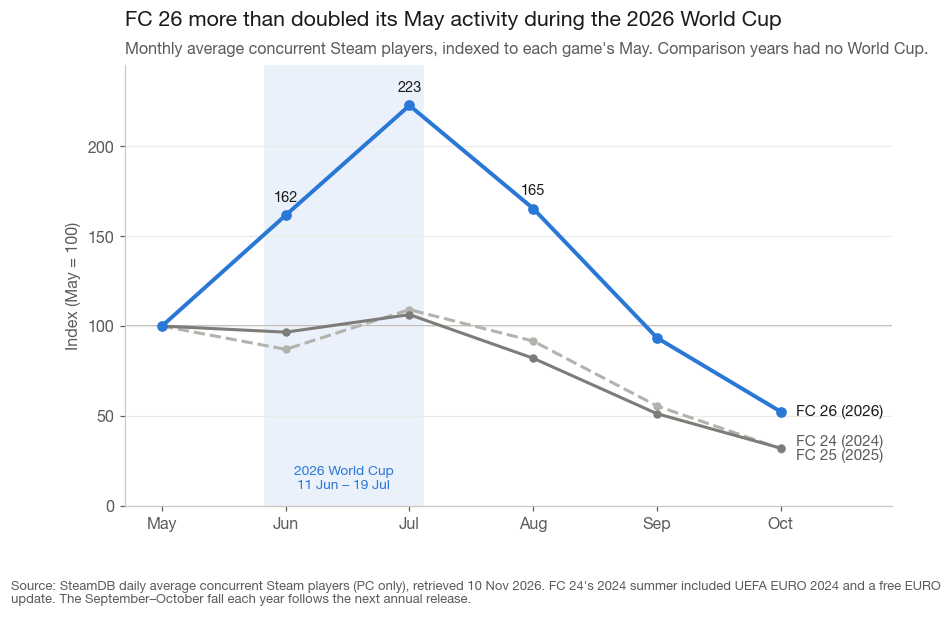

In [23]:
# Chart 1 - Summer comparison
fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(6)
ax.axvspan(1 - 0.5 + 10/30, 2 + 0.5 - 12/31, color=BAND, zorder=0)   # 11 Jun - 19 Jul, months centred on ticks
ax.text(1.47, 8, "2026 World Cup\n11 Jun – 19 Jul", ha="center", va="bottom", color=BLUE, fontsize=9)
styles = {"FC 24": (GREY_LIGHT, "--"), "FC 25": (GREY_DARK, "-")}
for g, y in SUMMER:
    s = summer[g]["index"].values
    if g == "FC 26":
        ax.plot(x, s, color=BLUE, lw=2.6, marker="o", ms=6, zorder=3)
        ax.text(5.12, s[-1], f"FC 26 (2026)", color=INK, va="center", fontsize=10, fontweight="bold")
        for i in (1, 2, 3):
            ax.annotate(f"{s[i]:.0f}", (x[i], s[i]), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9.5)
    else:
        c, ls = styles[g]
        ax.plot(x, s, color=c, lw=2, ls=ls, marker="o", ms=4.5, zorder=2)
        ax.text(5.12, s[-1] + (4 if g == "FC 24" else -4), f"{g} ({y})", color=INK_2, va="center", fontsize=10)
ax.axhline(100, color="#a9a8a2", lw=1, zorder=1)
ax.set_xticks(x, summer["FC 26"]["label"])
ax.set_xlim(-0.3, 5.9)
ax.set_ylim(0, 245)
ax.set_ylabel("Index (May = 100)")
finish(fig, ax, "FC 26 more than doubled its May activity during the 2026 World Cup",
       "Monthly average concurrent Steam players, indexed to each game's May. Comparison years had no World Cup.",
       SOURCE + " FC 24's 2024 summer included UEFA EURO 2024 and a free EURO update. "
       "The September–October fall each year follows the next annual release.")
fig.savefig(FIGURES / "chart_01_summer_comparison.png")
plt.show()

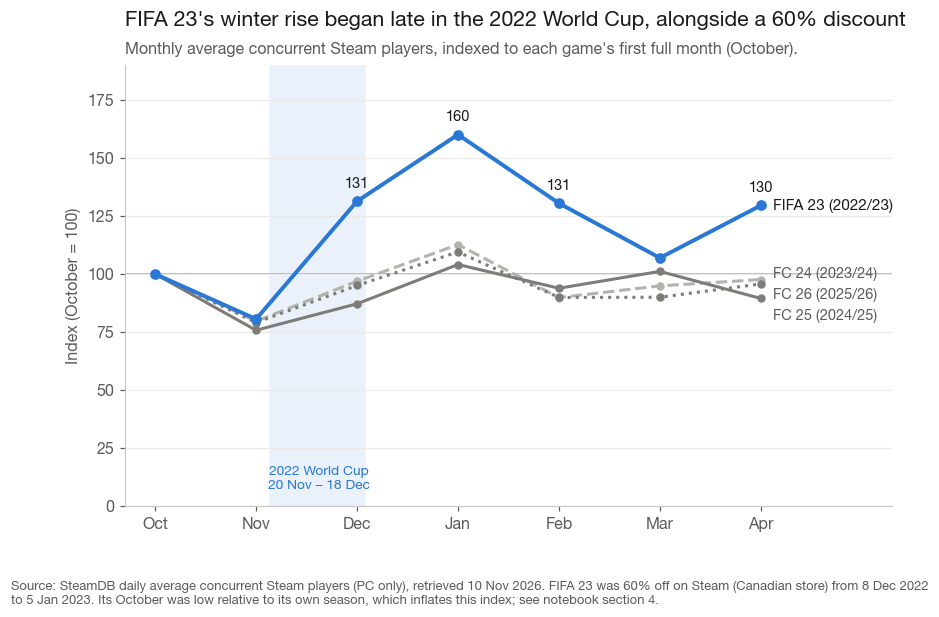

In [24]:
# Chart 2 - Winter comparison
fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(7)
ax.axvspan(1 - 0.5 + 19/30, 2 + 0.5 - 13/31, color=BAND, zorder=0)    # 20 Nov - 18 Dec 2022
ax.text(1.62, 6, "2022 World Cup\n20 Nov – 18 Dec", ha="center", va="bottom", color=BLUE, fontsize=9)
ctrl = {"FC 24": (GREY_LIGHT, "--"), "FC 25": (GREY_DARK, "-"), "FC 26": (GREY_DARK, ":")}
end_labels = {}
for g, y in WINTER:
    s = winter[g]["index"].values
    if g == "FIFA 23":
        ax.plot(x, s, color=BLUE, lw=2.6, marker="o", ms=6, zorder=3)
        for i in (2, 3, 4, 6):
            ax.annotate(f"{s[i]:.0f}", (x[i], s[i]), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9.5)
    else:
        c, ls = ctrl[g]
        ax.plot(x, s, color=c, lw=2, ls=ls, marker="o", ms=4.5, zorder=2)
    end_labels[g] = (s[-1], f"{g} ({y}/{str(y+1)[2:]})")
# spread the grey end labels so they don't collide
ctrl_sorted = sorted([(v, g) for g, (v, _) in end_labels.items() if g != "FIFA 23"])
for k, (v, g) in enumerate(ctrl_sorted):
    ax.text(6.12, 82 + k * 9, end_labels[g][1], color=INK_2, va="center", fontsize=9.5)
ax.text(6.12, end_labels["FIFA 23"][0], end_labels["FIFA 23"][1], color=INK, va="center", fontsize=10, fontweight="bold")
ax.axhline(100, color="#a9a8a2", lw=1, zorder=1)
ax.set_xticks(x, winter["FIFA 23"]["label"])
ax.set_xlim(-0.3, 7.3)
ax.set_ylim(0, 190)
ax.set_ylabel("Index (October = 100)")
finish(fig, ax, "FIFA 23's winter rise began late in the 2022 World Cup, alongside a 60% discount",
       "Monthly average concurrent Steam players, indexed to each game's first full month (October).",
       SOURCE + " FIFA 23 was 60% off on Steam (Canadian store) from 8 Dec 2022 to 5 Jan 2023. Its October was low "
       "relative to its own season, which inflates this index; see notebook section 4.")
fig.savefig(FIGURES / "chart_02_winter_comparison.png")
plt.show()

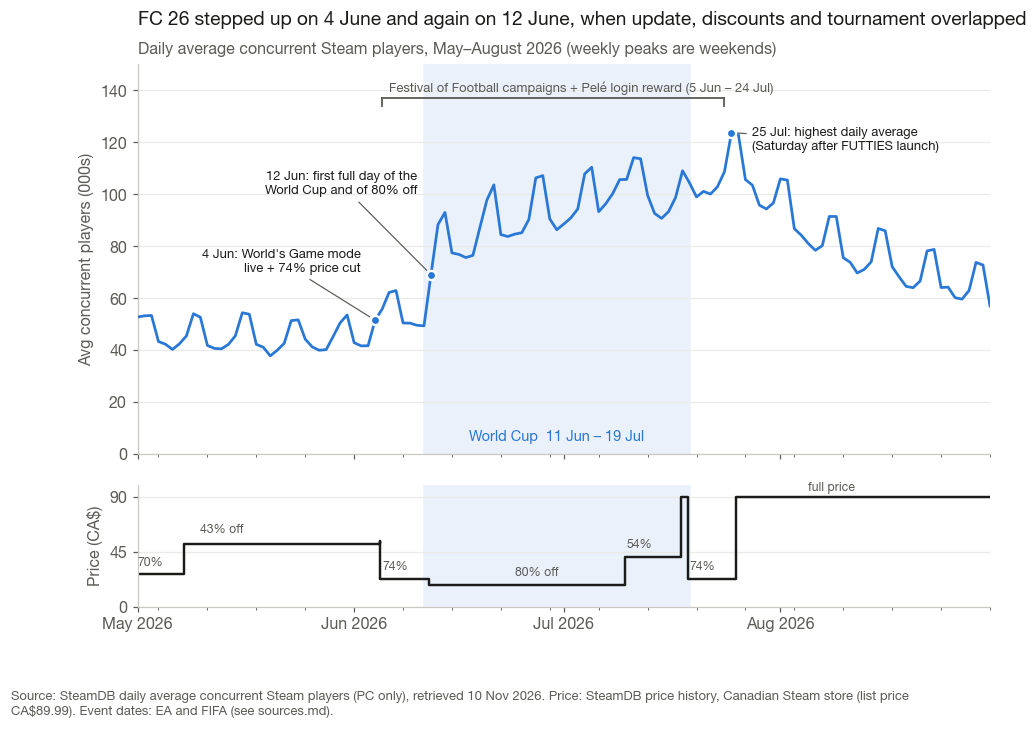

In [25]:
# Chart 3 - FC 26 daily activity with price and event timing
start, end = pd.Timestamp("2026-05-01"), pd.Timestamp("2026-08-31")
s = fc26.loc[start:end, "avg_players"] / 1000
p = price.set_index("DateTime")["Final price"]
p = pd.concat([pd.Series({start: p[:start].iloc[-1]}), p[start:end], pd.Series({end + pd.Timedelta(days=1): p[:end].iloc[-1]})])

fig, (ax, axp) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [3.2, 1], "hspace": 0.12})
for a in (ax, axp):
    a.axvspan(*WC_2026, color=BAND, zorder=0)
ax.plot(s.index, s.values, color=BLUE, lw=1.8, zorder=3)
ax.text(WC_2026[0] + (WC_2026[1] - WC_2026[0]) / 2, 4, "World Cup  11 Jun – 19 Jul", ha="center", va="bottom", color=BLUE, fontsize=9.5)

# Festival of Football + Pele login reward window drawn as a bracket
y_br = 137
ax.plot([FESTIVAL_2026[0], FESTIVAL_2026[1]], [y_br, y_br], color=INK_2, lw=1.2)
for d in FESTIVAL_2026:
    ax.plot([d, d], [y_br - 3, y_br], color=INK_2, lw=1.2)
ax.text(FESTIVAL_2026[0] + pd.Timedelta(days=1), y_br + 1.5, "Festival of Football campaigns + Pelé login reward (5 Jun – 24 Jul)",
        color=INK_2, fontsize=8.5, va="bottom")

notes = [("2026-06-04", "4 Jun: World's Game mode\nlive + 74% price cut", ("2026-06-02", 74), "right"),
         ("2026-06-12", "12 Jun: first full day of the\nWorld Cup and of 80% off", ("2026-06-10", 104), "right"),
         ("2026-07-25", "25 Jul: highest daily average\n(Saturday after FUTTIES launch)", ("2026-07-28", 121), "left")]
for d, label, (tx, ty), ha in notes:
    d = pd.Timestamp(d); yv = s[d]
    ax.annotate(label, (d, yv), xytext=(pd.Timestamp(tx), ty), ha=ha, va="center", fontsize=8.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8, shrinkA=2, shrinkB=4))
    ax.plot(d, yv, "o", ms=6, color=BLUE, markeredgecolor="white", markeredgewidth=1.5, zorder=4)
ax.set_ylim(0, 150)
ax.set_ylabel("Avg concurrent players (000s)")
ax.set_title("FC 26 stepped up on 4 June and again on 12 June, when update, discounts and tournament overlapped",
             pad=26, color=INK, fontsize=12.5)
ax.text(0, 1.02, "Daily average concurrent Steam players, May–August 2026 (weekly peaks are weekends)",
        transform=ax.transAxes, color=INK_2, fontsize=10.5, va="bottom")

axp.step(p.index, p.values, where="post", color=INK, lw=1.6)
axp.set_ylim(0, 100)
axp.set_yticks([0, 45, 90])
axp.set_ylabel("Price (CA$)")
for d, lbl, yy in [("2026-05-01", "70%", 31), ("2026-05-10", "43% off", 58), ("2026-06-05", "74%", 28), ("2026-06-24", "80% off", 23),
                   ("2026-07-10", "54%", 46), ("2026-07-19", "74%", 28), ("2026-08-05", "full price", 93)]:
    axp.text(pd.Timestamp(d), yy, lbl, fontsize=8, color=INK_2, va="bottom")
axp.xaxis.set_major_locator(mdates.MonthLocator())
axp.xaxis.set_minor_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axp.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axp.set_xlim(start, end)
fig.text(0.01, -0.01, textwrap.fill(SOURCE + " Price: SteamDB price history, Canadian Steam store (list price CA$89.99). "
         "Event dates: EA and FIFA (see sources.md).", 160), color=INK_2, fontsize=8.5, ha="left", va="top")
fig.savefig(FIGURES / "chart_03_fc26_daily_events.png")
plt.show()

## 8. Figures used in the README

The numbers quoted in the README, recomputed here so they can be checked.

In [26]:
key = {
    "FC 26 Jun/Jul index (May=100)": summer_tbl.loc[["Jun", "Jul"], "FC 26 (2026)"].tolist(),
    "FC 24/FC 25 Jul index": summer_tbl.loc["Jul", ["FC 24 (2024)", "FC 25 (2025)"]].tolist(),
    "FC 26 Jul avg players": int(summer["FC 26"].set_index("label").loc["Jul", "avg_players"]),
    "FIFA 23 Dec/Jan index (Oct=100)": winter_tbl.loc[["Dec", "Jan"], "FIFA 23 (2022/23)"].tolist(),
    "Control Dec index range": [winter_tbl.loc["Dec"].iloc[1:4].min(), winter_tbl.loc["Dec"].iloc[1:4].max()],
    "FIFA 23 Feb-Apr index": winter_tbl.loc[["Feb", "Mar", "Apr"], "FIFA 23 (2022/23)"].tolist(),
    "Kick-off window change % (FC 26, 25, 24)": event_tbl.loc[1, ["FC 26 (2026) %", "FC 25 same dates 2025 %", "FC 24 same dates 2024 %"]].tolist(),
    "Mar 5 cut change %": float(cuts.loc[cuts["date"] == "2026-03-05", "change_pct"].round(1).iloc[0]),
    "Oct index (May=100)": persist["Oct index (May=100)"].tolist(),
}
for k, v in key.items():
    print(f"{k}: {v}")

FC 26 Jun/Jul index (May=100): [162.0, 223.0]
FC 24/FC 25 Jul index: [109.0, 106.0]
FC 26 Jul avg players: 102075
FIFA 23 Dec/Jan index (Oct=100): [131.0, 160.0]
Control Dec index range: [87.0, 97.0]
FIFA 23 Feb-Apr index: [131.0, 107.0, 130.0]
Kick-off window change % (FC 26, 25, 24): [45.4, -4.6, -4.6]
Mar 5 cut change %: 12.8
Oct index (May=100): [32.0, 32.0, 52.0]
